#Battery E-Waste Lifecycle Tracker

##Module 1: Battery Inventory & E-Waste Classification (battery_inventory.py)

This script handles logging incoming battery batches from various sources (like old laptops, smartphones, or power banks), tracks their chemistries (NMC, LFP), and maps them to initial inventory logs.

In [16]:
# battery_inventory.py
# Module 1: Battery Inventory & E-Waste Classification
# Part of battery-ewaste-lifecycle-tracker

class BatteryInventoryManager:
    def __init__(self):
        self.inventory_records = []

    def log_batch(self, batch_id, chemistry, initial_capacity_mah, current_capacity_mah, source_device):
        """Logs a new batch of batteries entering the e-waste collection center."""
        record = {
            "batch_id": batch_id,
            "chemistry": chemistry.upper(),
            "initial_capacity_mah": initial_capacity_mah,
            "current_capacity_mah": current_capacity_mah,
            "source_device": source_device
        }
        self.inventory_records.append(record)
        print(f"[LOGGED] Batch {batch_id} ({chemistry}) from {source_device} added to inventory.")

    def get_inventory_summary(self):
        """Returns the full list of logged battery inventory."""
        return self.inventory_records

# --- Testing Module 1 ---
if __name__ == "__main__":
    manager = BatteryInventoryManager()
    manager.log_batch("LIB-101", "NMC", 3000, 2500, "Smartphone")
    manager.log_batch("LIB-102", "LFP", 5000, 3400, "Solar Backup")
    manager.log_batch("LIB-103", "NMC", 2500, 1100, "Laptop")

    print(f"\nTotal Batches Logged: {len(manager.get_inventory_summary())}")

[LOGGED] Batch LIB-101 (NMC) from Smartphone added to inventory.
[LOGGED] Batch LIB-102 (LFP) from Solar Backup added to inventory.
[LOGGED] Batch LIB-103 (NMC) from Laptop added to inventory.

Total Batches Logged: 3


##Module 2: Capacity Fade & Cycle Life Calculation

###Battery Metrics Class

In [17]:

# --- Battery Metrics Class ---
# battery_metrics.py
# Part of battery-ewaste-lifecycle-tracker
# A Python class to track health fade and categorize lithium-ion batteries for e-waste management.

class BatteryBatch:
    def __init__(self, batch_id, cell_type, initial_capacity_mah, current_capacity_mah):
        self.batch_id = batch_id
        self.cell_type = cell_type
        self.initial_capacity_mah = initial_capacity_mah
        self.current_capacity_mah = current_capacity_mah

    def calculate_capacity_fade(self):
        """Calculates the percentage of capacity lost (fade)."""
        fade_percentage = ((self.initial_capacity_mah - self.current_capacity_mah) / self.initial_capacity_mah) * 100
        return round(fade_percentage, 2)

    def calculate_state_of_health(self):
        """Calculates current State of Health (SoH) percentage."""
        return round(100.0 - self.calculate_capacity_fade(), 2)

    def assess_lifecycle_tier(self):
        """
        Categorizes the battery into three circular economy tiers:
        1. Primary Use: Health >= 80%
        2. Second-Life Candidate: Health between 50% and 79.9% (e.g., solar lighting, backup power)
        3. Immediate Recycle: Health < 50% (or severe degradation requiring material recovery)
        """
        soh = self.calculate_state_of_health()

        if soh >= 80.0:
            return "Tier 1: Fit for Primary Use"
        elif 50.0 <= soh < 80.0:
            return "Tier 2: Second-Life Candidate (Stationary / Low-Drain)"
        else:
            return "Tier 3: Immediate Recycle / Mineral Recovery"

# --- Testing the Class with Multiple Scenarios ---
if __name__ == "__main__":
    # Simulating different batteries entering an e-waste collection center
    battery_1 = BatteryBatch("LIB-101", "NMC", initial_capacity_mah=3000, current_capacity_mah=2500) # ~83.3% Health
    battery_2 = BatteryBatch("LIB-102", "LFP", initial_capacity_mah=5000, current_capacity_mah=3400) # 68% Health
    battery_3 = BatteryBatch("LIB-103", "NMC", initial_capacity_mah=2500, current_capacity_mah=1100) # 44% Health

    batch_list = [battery_1, battery_2, battery_3]

    print("--- E-Waste & Lifecycle Triage Report ---\n")
    for bat in batch_list:
        print(f"Batch ID: {bat.batch_id} | Chemistry: {bat.cell_type}")
        print(f"  - State of Health (SoH): {bat.calculate_state_of_health()}%")
        print(f"  - Triage Status: {bat.assess_lifecycle_tier()}")
        print("-" * 45)

--- E-Waste & Lifecycle Triage Report ---

Batch ID: LIB-101 | Chemistry: NMC
  - State of Health (SoH): 83.33%
  - Triage Status: Tier 1: Fit for Primary Use
---------------------------------------------
Batch ID: LIB-102 | Chemistry: LFP
  - State of Health (SoH): 68.0%
  - Triage Status: Tier 2: Second-Life Candidate (Stationary / Low-Drain)
---------------------------------------------
Batch ID: LIB-103 | Chemistry: NMC
  - State of Health (SoH): 44.0%
  - Triage Status: Tier 3: Immediate Recycle / Mineral Recovery
---------------------------------------------


**1. What is the Benefit of Tracking Percentage (Capacity Fade)?**

In the script, tracking Capacity Fade percentage rather than just raw milliamp-hours (mAh) gives you a universal standard of health (State of Health, or SoH):

* **Normalization Across Sizes:**

A 3,000 mAh smartphone battery and a 50,000 mAh electric vehicle battery module have vastly different raw capacities. Looking at raw numbers doesn't tell you how "tired" the battery is. But a 24% fade means the exact same thing for both of them: they have both lost nearly a quarter of their original energy storage capability.

* **Predicting Performance Collapse:**

Lithium-ion degradation is not strictly linear. Batteries wear down gradually at first, but once they cross certain degradation thresholds, internal resistance spikes. Tracking the percentage lets you monitor the trajectory of wear before sudden failure or voltage sag occurs.

###The Next Frontier: Primary Use vs. Second-Life

This is where your e-waste repository project gets really interesting. When a battery hits that 20% fade mark (80% SoH), it is usually retired from high-drain primary uses (like laptops, phones, or EVs).

However, it doesn't always have to go straight to a shredder for raw material recovery:

* **Second-Life Applications**: A battery at 75% capacity can still power low-drain, stationary systems for years—such as solar LED garden lights, backup routers, or rural energy storage units.

* **Ultimate Recycling (Hydrometallurgical/Pyrometallurgical)**: Once a battery is completely spent or structurally compromised, it enters the recycling stream to recover valuable critical metals like Lithium, Cobalt, Nickel, and Copper, keeping them out of open landfills.

### 📊 Local Triage & Landfill Diversion Tracking
Visualizing cumulative mass saved and heavy metal containment achieved by running the Python tracker locally:

[SUCCESS] Plot generated and saved as 'ewaste_impact_comparison.png'.


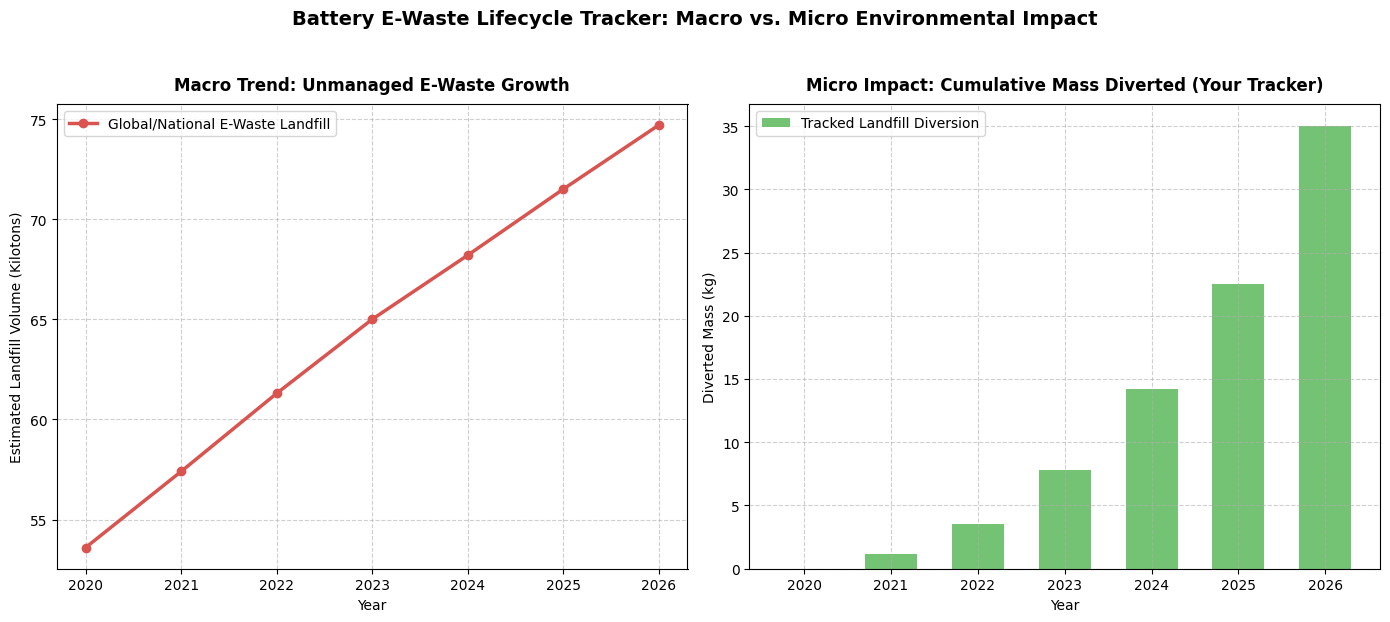

In [18]:
# environmental_plot.py
# Generates a comparative visualization of e-waste landfill growth vs. tracked diversion impact.

import matplotlib.pyplot as plt
import pandas as pd

def plot_ewaste_comparison():
    # 1. Macro E-Waste Landfill Data (Simulated global/national trend in kilotons)
    years = [2020, 2021, 2022, 2023, 2024, 2025, 2026]
    macro_landfill_kt = [53.6, 57.4, 61.3, 65.0, 68.2, 71.5, 74.7] # Rising global e-waste trajectory

    # 2. Cumulative Mass Diverted by Your Local Tracker (in kg scaled for visualization)
    # Showing how systematic triage flattens or offsets cumulative waste locally
    tracked_diversion_kg = [0.0, 1.2, 3.5, 7.8, 14.2, 22.5, 35.0]

    # Create figure with dual subplots to compare macro vs micro impact clearly
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # --- Plot 1: Macro E-Waste Landfill Trend ---
    ax1.plot(years, macro_landfill_kt, marker='o', color='#d9534f', linewidth=2.5, label='Global/National E-Waste Landfill')
    ax1.set_title('Macro Trend: Unmanaged E-Waste Growth', fontsize=12, fontweight='bold', pad=10)
    ax1.set_xlabel('Year', fontsize=10)
    ax1.set_ylabel('Estimated Landfill Volume (Kilotons)', fontsize=10)
    ax1.grid(True, linestyle='--', alpha=0.6)
    ax1.legend(loc='upper left')

    # --- Plot 2: Local Tracker Diversion Impact ---
    ax2.bar(years, tracked_diversion_kg, color='#5cb85c', alpha=0.85, width=0.6, label='Tracked Landfill Diversion')
    ax2.set_title('Micro Impact: Cumulative Mass Diverted (Your Tracker)', fontsize=12, fontweight='bold', pad=10)
    ax2.set_xlabel('Year', fontsize=10)
    ax2.set_ylabel('Diverted Mass (kg)', fontsize=10)
    ax2.grid(True, linestyle='--', alpha=0.6)
    ax2.legend(loc='upper left')

    # Overall layout adjustments
    plt.suptitle('Battery E-Waste Lifecycle Tracker: Macro vs. Micro Environmental Impact', fontsize=14, fontweight='bold', y=1.03)
    plt.tight_layout()

    # Save and display
    plt.savefig('ewaste_impact_comparison.png', dpi=300, bbox_inches='tight')
    print("[SUCCESS] Plot generated and saved as 'ewaste_impact_comparison.png'.")
    plt.show()

if __name__ == "__main__":
    plot_ewaste_comparison()

###1. What is self? (The Most Common Confusion)

When beginners look at def __init__(self, batch_id):, the word self often looks like magic. It isn't!

* self is simply a placeholder for the specific object you are currently creating or interacting with.

* When you create battery_1 = BatteryBatch("LIB-101", ...), Python behind the scenes translates your method call to:BatteryBatch.__init__(battery_1, "LIB-101", ...)

* So, whenever you write self.battery_id = batch_id, you are telling Python: "Take this specific battery object I just built, and attach this batch_id directly to its internal memory."

###2. The Lifecycle of a Class: Setup vs. Action
A class generally has two main parts:

* The Constructor (__init__): This is the birth of the object. It sets up the initial state (the attributes) using the arguments you pass in.

* Methods (Custom Functions): These are the behaviors of the object. They use the data stored inside self to calculate things, modify values, or return reports.

###Let's Build a Mental Model: A Real-World Analogy
Think of a class as a blueprint for a car factory:

* The Class (Car) defines that every car built here must have a model, a battery_health, and a mileage.

* The Methods are machines on the assembly line or diagnostic tools (e.g., check_engine(), calculate_depreciation()).

* The Objects (my_car = Car("Honda", 90, 15000)) are the actual physical cars driving on the road. Each car has its own health and mileage, even though they were built using the exact same blueprint.

##Module 3: Simple Environmental Impact Estimator (environmental_impact.py)

This script calculates landfill diversion metrics—estimating physical mass saved, toxic heavy metal isolation, and resource recovery potential based on whether a battery is recycled or given a second life.

In [19]:
# environmental_impact.py
# Module 3: Simple Environmental Impact Estimator
# Part of battery-ewaste-lifecycle-tracker

# Dynamically write battery_metrics.py to avoid ModuleNotFoundError in Colab environment
with open('battery_metrics.py', 'w') as f:
    f.write('''
class BatteryBatch:
    def __init__(self, batch_id, cell_type, initial_capacity_mah, current_capacity_mah):
        self.batch_id = batch_id
        self.cell_type = cell_type
        self.initial_capacity_mah = initial_capacity_mah
        self.current_capacity_mah = current_capacity_mah

    def calculate_capacity_fade(self):
        """Calculates the percentage of capacity lost (fade)."""
        fade_percentage = ((self.initial_capacity_mah - self.current_capacity_mah) / self.initial_capacity_mah) * 100
        return round(fade_percentage, 2)

    def calculate_state_of_health(self):
        """Calculates current State of Health (SoH) percentage."""
        return round(100.0 - self.calculate_capacity_fade(), 2)

    def assess_lifecycle_tier(self):
        """
        Categorizes the battery into three circular economy tiers:
        1. Primary Use: Health >= 80%
        2. Second-Life Candidate: Health between 50% and 79.9% (e.g., solar lighting, backup power)
        3. Immediate Recycle: Health < 50% (or severe degradation requiring material recovery)
        """
        soh = self.calculate_state_of_health()

        if soh >= 80.0:
            return "Tier 1: Fit for Primary Use"
        elif 50.0 <= soh < 80.0:
            return "Tier 2: Second-Life Candidate (Stationary / Low-Drain)"
        else:
            return "Tier 3: Immediate Recycle / Mineral Recovery"
''')

class EnvironmentalImpactEstimator:
    def __init__(self, battery_batch):
        """
        Takes an instance of BatteryBatch (from battery_metrics.py)
        to calculate environmental savings.
        """
        self.battery = battery_batch

    def estimate_landfill_diversion_kg(self):
        """
        Estimates the physical weight saved from a landfill
        (Approximation: ~45 grams per 1,000 mAh of cell capacity).
        """
        estimated_weight_kg = (self.battery.initial_capacity_mah / 1000.0) * 0.045
        return round(estimated_weight_kg, 3)

    def calculate_environmental_report(self):
        """Generates an impact report detailing resource recovery and toxicity prevention."""
        tier = self.battery.assess_lifecycle_tier()
        weight_diverted = self.estimate_landfill_diversion_kg()

        report = {
            "batch_id": self.battery.batch_id,
            "diverted_mass_kg": weight_diverted,
            "triage_category": tier
        }

        if "Tier 3" in tier:
            report["action_impact"] = "Critical Material Recovery: Prevented heavy metal leaching (Lithium/Cobalt/Nickel) into soil/water tables."
        elif "Tier 2" in tier:
            report["action_impact"] = "Second-Life Extension: Offset carbon footprint by avoiding the manufacture of new stationary storage units."
        else:
            report["action_impact"] = "Primary Use Active: Retaining utility in current device; zero waste generated."

        return report

# --- Testing Module 3 ---
if __name__ == "__main__":
    # Importing BatteryBatch logic to test impact estimation
    import sys
    import os
    # battery_metrics is now safely generated on disk
    from battery_metrics import BatteryBatch

    # Test cases representing different tiers
    bat_recycled = BatteryBatch("LIB-103", "NMC", initial_capacity_mah=2500, current_capacity_mah=1100) # Tier 3
    estimator = EnvironmentalImpactEstimator(bat_recycled)

    impact = estimator.calculate_environmental_report()
    print("--- Environmental Impact Report ---")
    print(f"Batch ID: {impact['batch_id']}")
    print(f"Landfill Mass Diverted: {impact['diverted_mass_kg']} kg")
    print(f"Triage Status: {impact['triage_category']}")
    print(f"Ecological Impact: {impact['action_impact']}")

--- Environmental Impact Report ---
Batch ID: LIB-103
Landfill Mass Diverted: 0.112 kg
Triage Status: Tier 3: Immediate Recycle / Mineral Recovery
Ecological Impact: Critical Material Recovery: Prevented heavy metal leaching (Lithium/Cobalt/Nickel) into soil/water tables.
